In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [49]:
run_name = "tinystories-base-64b"

In [50]:
df = pd.read_json(f"../runs/{run_name}/metrics.jsonl", lines=True)
df

,step,time,train_loss,lr,val_loss
0,10,15.060000,8.469139,0.000167,NaN
1,20,28.660000,6.913788,0.000333,NaN
2,10,15.120000,8.427797,0.000167,NaN
3,20,28.550000,6.843823,0.000333,NaN
4,30,42.050000,5.369480,0.000500,NaN
5,40,55.610000,4.528574,0.000667,NaN
6,50,69.040000,4.006947,0.000833,NaN
7,100,135.700000,3.243624,0.000999,NaN
8,200,273.550000,2.700935,0.000993,NaN
9,300,408.010000,2.429947,0.000979,NaN


In [51]:
train = df[df["train_loss"].notna()]
train

,step,time,train_loss,lr,val_loss
0,10,15.06,8.469139,0.000167,NaN
1,20,28.66,6.913788,0.000333,NaN
2,10,15.12,8.427797,0.000167,NaN
3,20,28.55,6.843823,0.000333,NaN
4,30,42.05,5.369480,0.000500,NaN
5,40,55.61,4.528574,0.000667,NaN
6,50,69.04,4.006947,0.000833,NaN
7,100,135.70,3.243624,0.000999,NaN
8,200,273.55,2.700935,0.000993,NaN
9,300,408.01,2.429947,0.000979,NaN


In [52]:
val = df[df["val_loss"].notna()]
val

,step,time,train_loss,lr,val_loss
12,500,684.657779,NaN,NaN,2.170043
18,1000,1397.788436,NaN,NaN,1.924660
24,1500,2076.806563,NaN,NaN,1.775767
30,2000,2751.078369,NaN,NaN,1.677184
36,2500,3447.125477,NaN,NaN,1.667263


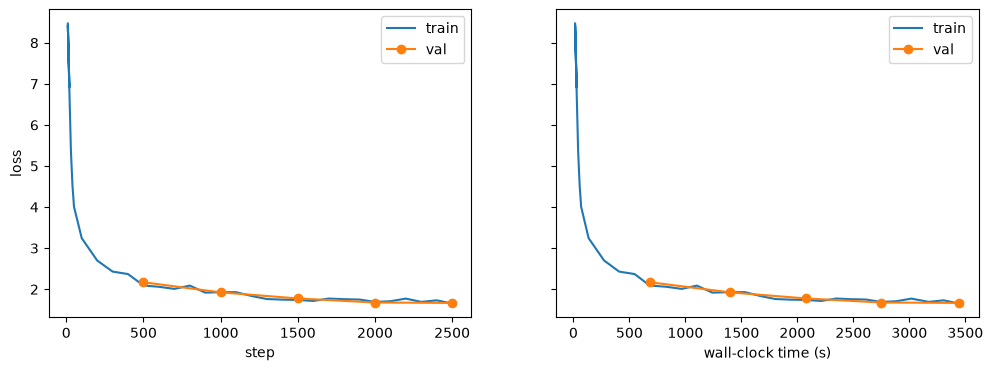

In [53]:
fig, (ax_step, ax_time) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, x in [(ax_step, "step"), (ax_time, "time")]:
    ax.plot(train[x], train["train_loss"], label="train")
    ax.plot(val[x], val["val_loss"], label="val", marker="o")
    ax.set_xlabel("step" if x == "step" else "wall-clock time (s)")
    ax.legend()

ax_step.set_ylabel("loss")
fig.savefig(f"../runs/{run_name}/loss.png", dpi=150, bbox_inches="tight")
plt.show()

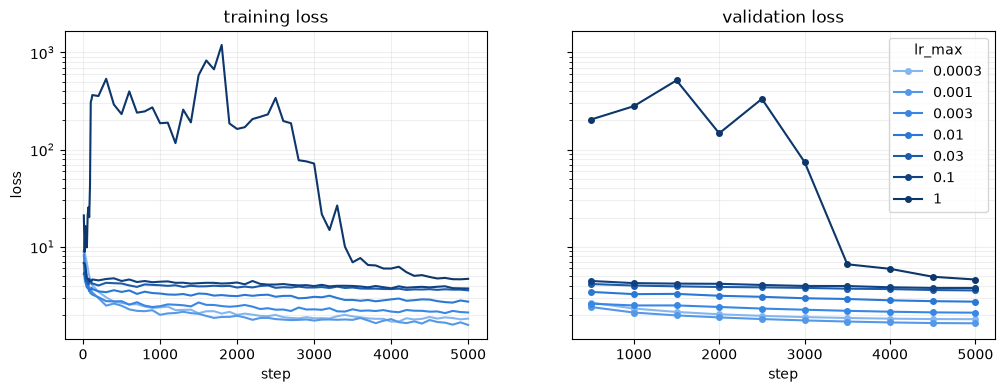

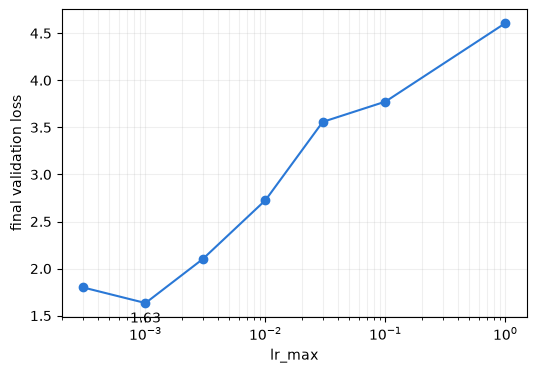

In [48]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

runs_dir = "../runs"
run_names = ["tinystories-base-32b"] + [os.path.basename(p) for p in glob.glob(f"{runs_dir}/tinystories-lr-*")]

runs = []
for run_name in run_names:
    with open(f"{runs_dir}/{run_name}/config.json") as f:
        lr = json.load(f)["optimizer_lr_max"]
    df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
    runs.append((lr, df))
runs.sort(key=lambda run: run[0])

# One blue ramp: light = low learning rate, dark = high learning rate
ramp = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
colors = [ramp[i] for i in np.linspace(0, len(ramp) - 1, len(runs)).round().astype(int)]

fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for (lr, df), color in zip(runs, colors):
    train = df[df["train_loss"].notna()]
    val = df[df["val_loss"].notna()]
    ax_train.plot(train["step"], train["train_loss"], color=color, linewidth=1.5, label=f"{lr:g}")
    ax_val.plot(val["step"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=4, label=f"{lr:g}")

for ax, title in [(ax_train, "training loss"), (ax_val, "validation loss")]:
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.2)
    # ax.set_ylim(1.4, 10)  # uncomment to zoom in on the runs that converged

ax_train.set_ylabel("loss")
ax_val.legend(title="lr_max")
fig.savefig(f"{runs_dir}/lr_sweep_curves.png", dpi=150, bbox_inches="tight")
plt.show()

final = [(lr, df["val_loss"].dropna().iloc[-1]) for lr, df in runs]
lrs, final_losses = zip(*final)
best_lr, best_loss = min(final, key=lambda run: run[1])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(lrs, final_losses, color="#2a78d6", linewidth=1.5, marker="o", markersize=6)
ax.annotate(f"{best_loss:.2f}", (best_lr, best_loss), textcoords="offset points", xytext=(0, -14), ha="center")
ax.set_xscale("log")
ax.set_xlabel("lr_max")
ax.set_ylabel("final validation loss")
ax.grid(True, which="both", alpha=0.2)
fig.savefig(f"{runs_dir}/lr_sweep_final.png", dpi=150, bbox_inches="tight")
plt.show()